# 04 – Validation against Sentinel-1 (E3)

The flood map is run at the daily-mean Tan Chau stage of six flood-season Sentinel-1 scenes (2022–2025, 2.74–3.75 m,
all outside the JRC period used for calibration) and compared with the observed water extent. Water masks were rebuilt
from the scenes (Supplement S5): Microsoft Planetary Computer → projection to the 64 m grid → median filter → Otsu →
opening/closing; permanent water from three April 2024 scenes. The masks are stored in
`data/derived/sentinel1_water_masks.npz`; `fetch_scenes` + `build_masks` recreate them from the open archive.

In [1]:
import sys
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
pd.options.display.float_format = "{:,.3f}".format
from analysis.flood_model import FloodModel
from analysis.sar_validation import Sentinel1Validation, SCENES
fm = FloodModel(ROOT / "data/derived/grids_public.npz", ROOT / "data/mrc_derived/calib.json")
v = Sentinel1Validation(fm, ROOT / "data/derived/sentinel1_water_masks.npz")
print(f"comparison domain: {v.domain_km2:,.0f} km2 (paper: 2,126)")

comparison domain: 2,147 km2 (paper: 2,126)


## Table `e3` – map against SAR, calibrated map vs DEM-only baseline

In [2]:
v.table()

,date,satellite,stage_m,IoU,F1,precision,recall,IoU_DEM,map_km2,SAR_km2,rho_map,rho_DEM
0,2023-10-20,S1A,2.740,0.536,0.698,0.838,0.597,0.244,558.567,783.805,0.544,0.221
1,2024-10-02,S1A,3.110,0.591,0.743,0.756,0.731,0.416,721.978,746.284,0.720,0.465
2,2025-10-03,S1C,3.400,0.551,0.710,0.657,0.773,0.463,842.299,715.971,0.659,0.469
3,2022-10-13,S1A,3.490,0.569,0.725,0.692,0.762,0.501,880.850,799.542,0.723,0.546
4,2025-10-15,S1C,3.670,0.501,0.668,0.558,0.832,0.440,990.098,664.566,0.639,0.661
5,2025-10-09,S1A,3.750,0.528,0.691,0.581,0.851,0.455,"1,026.305",701.159,0.593,0.551


## Where map and SAR agree

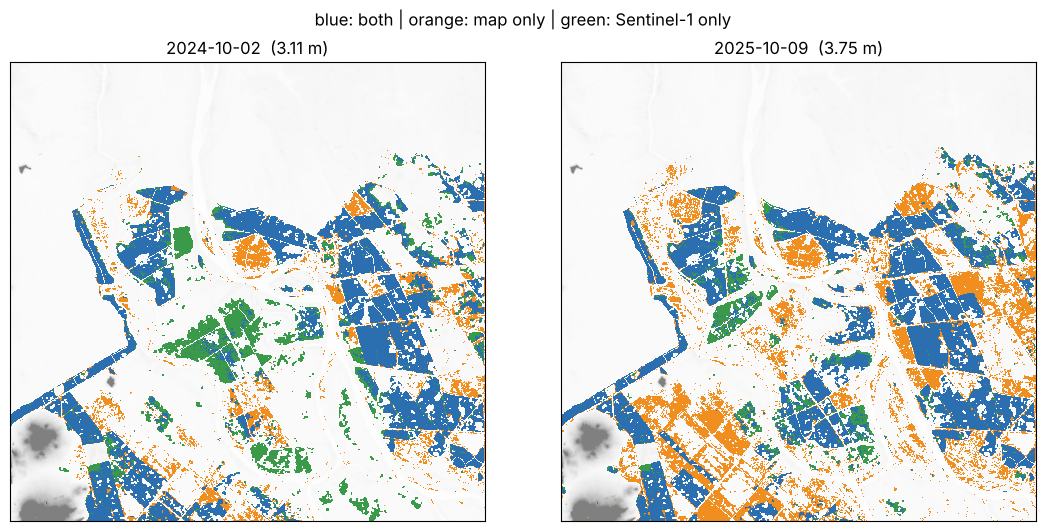

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5.2), constrained_layout=True)
ext = [fm.grid.west, fm.grid.east, fm.grid.south, fm.grid.north]
from matplotlib.colors import ListedColormap
cmap = ListedColormap(["#ffffff00", "#2b6fb0", "#f08f1f", "#3a9a4a"])    # none, both, map only, SAR only
for ax, date in zip(axes, ["2024-10-02", "2025-10-09"]):
    L = SCENES[date][1]
    _, d = fm.flood(L)
    pm, so = (d > 0) & v.domain, v.masks[date] & v.domain
    cat = np.where(pm & so, 1, np.where(pm, 2, np.where(so, 3, 0)))
    ax.imshow(np.where(fm.elev0 < 60, fm.elev0, 60), cmap="Greys", vmin=-2, vmax=60, extent=ext, alpha=.5)
    ax.imshow(cat, cmap=cmap, vmin=0, vmax=3, extent=ext, interpolation="nearest")
    ax.set_title(f"{date}  ({L:.2f} m)"); ax.set_xticks([]); ax.set_yticks([])
fig.suptitle("blue: both | orange: map only | green: Sentinel-1 only")
plt.show()

## Sensitivity to the water threshold

The paper states that moving the Otsu threshold by ±2 dB changes IoU by at most 0.04. Recomputing from the rebuilt
masks (needs the projected scenes from `fetch_scenes`): five of six scenes stay within 0.04; the 20 October 2023 scene
(lowest stage, 2.74 m) changes by +0.05 / −0.08. That sentence of the paper should be checked.